# Google Colab edition

Run the setup cell first, then work from top to bottom. Keep the course ZIP in My Drive. Use a fresh Colab runtime when switching dependency profiles. **Select a GPU runtime before running this notebook.** 

Original fast.ai Lessons 9–10 material. A GPU and model downloads are required. The textual-inversion inference example uses the bundled course embedding unless you supply your own trained embedding. Generated images appear in notebook outputs; save the notebook to retain them.

Source: https://github.com/fastai/diffusion-nbs/blob/f565e05aae20b3c0cf958de29c21776572e38505/Stable Diffusion Deep Dive.ipynb

In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '04_fastai_part2/diffusion_intro', 'diffusion', '02_stable_diffusion_deep_dive.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)

# Diffusion inference does not use the training hooks. Capture its baseline
# before any exercise cell so the unchanged helper mutation guard can verify it.
from course_persistence import prepare_reuse_evidence as _prepare_diffusion_reuse_evidence
_prepare_diffusion_reuse_evidence(COLAB_CONTEXT)


Exercise folder: /content/HaiLong_Colab_Exercises/04_fastai_part2/diffusion_intro
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/04_fastai_part2/diffusion_intro/results


## Full exercise evidence

- Run all exercise cells top to bottom in hosted Colab and preserve their outputs, errors and execution counts.
- Keep QUICK_RUN=False; shortened checks or synthetic replacements for real datasets do not count as full original exercises.
- Preserve plots, models, metrics and run configurations in Drive; a final-cell marker alone is insufficient.
- Retain original datasets, model definitions, training schedules and instructional comparisons.
- Run prerequisite checkpoint-producing notebooks first; do not replace missing weights with untrained models.

- Run all four added original-prompt parameter comparisons with their recorded shared controls and complete schedules; retain20 generated images,4 grids,4 comparison CSVs,15 step traces and task JSON. Interpret actual images yourself; pixel statistics do not certify visual quality.

This cell describes evidence to collect; it does not certify completion. GPU batch caps preserve dataset coverage and epoch counts, but are documented configuration changes.


# Stable Diffusion Deep Dive

Stable Diffusion is a powerful text-to-image model. There are various websites and tools to make using it as easy as possible. It is also [integrated into the Huggingface diffusers library](https://huggingface.co/blog/stable_diffusion) where generating images can be as simple as:
```python
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained("CompVis/stable-diffusion-v1-4", variant="fp16", torch_dtype=torch.float16, use_auth_token=True).to("cuda")
image = pipe("An astronaught scuba diving").images[0]

```

In this notebook we're going to dig into the code behind these easy-to-use interfaces, to see what is going on under the hood. We'll begin by re-creating the functionality above as a scary chunk of code, and then one by one we'll inspect the different components and figure out what they do. By the end of this notebook that same sampling loop should feel like something you can tweak and modify as you like.

## Setup & Imports

You'll need to log into huggingface and accept the terms of the licence for this model - see the [model card](https://huggingface.co/CompVis/stable-diffusion-v1-4) for details. And when you first run this notebook you need to uncomment the following two cells to install the requirements and log in to huggingface with an access token.

In [2]:
# !pip install -q --upgrade transformers==4.25.1 diffusers ftfy accelerate

In [3]:
from base64 import b64encode

import numpy
import torch
from diffusers import AutoencoderKL, LMSDiscreteScheduler, UNet2DConditionModel
from huggingface_hub import notebook_login

# For video display:
from IPython.display import HTML
from matplotlib import pyplot as plt
from pathlib import Path
from PIL import Image
from torch import autocast
from torchvision import transforms as tfms
from tqdm.auto import tqdm
from transformers import CLIPTextModel, CLIPTokenizer, logging
import os

torch.manual_seed(1)
# Public model downloads do not need a token. Use notebook_login() only if a chosen model requires one.

# Supress some unnecessary warnings when loading the CLIPTextModel
logging.set_verbosity_error()

# Set device
torch_device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
if "mps" == torch_device: os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = "1"

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


## Loading the models

This code (and that in the next section) comes from the [Huggingface example notebook](https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/stable_diffusion.ipynb).

This will download and set up the relevant models and components we'll be using. Let's just run this for now and move on to the next section to check that it all works before diving deeper.

If you've loaded a pipeline, you can also access these components using `pipe.unet`, `pipe.vae` and so on.

In this notebook we aren't doing any memory-saving tricks - if you find yourself running out of GPU RAM, look at the pipeline code for inspiration with things like attention slicing, switching to half precision (fp16), keeping the VAE on the CPU and other modifications.

In [4]:
# Load the autoencoder model which will be used to decode the latents into image space.
vae = AutoencoderKL.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="vae")

# Load the tokenizer and text encoder to tokenize and encode the text.
tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14")
text_encoder = CLIPTextModel.from_pretrained("openai/clip-vit-large-patch14")

# The UNet model for generating the latents.
unet = UNet2DConditionModel.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="unet")

# The noise scheduler
scheduler = LMSDiscreteScheduler(beta_start=0.00085, beta_end=0.012, beta_schedule="scaled_linear", num_train_timesteps=1000)

# To the GPU we go!
vae = vae.to(torch_device)
text_encoder = text_encoder.to(torch_device)
unet = unet.to(torch_device);

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


## A diffusion loop

If all you want is to make a picture with some text, you could ignore this notebook and use one of the existing tools (such as [DreamStudio](https://beta.dreamstudio.ai/)) or use the simplified pipeline from huggingface, as documented [here](https://huggingface.co/blog/stable_diffusion).

What we want to do in this notebook is dig a little deeper into how this works, so we'll start by checking that the example code runs. Again, this is adapted from the [HF notebook](https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/stable_diffusion.ipynb) and looks very similar to what you'll find if you inspect [the `__call__()` method of the stable diffusion pipeline](https://github.com/huggingface/diffusers/blob/main/src/diffusers/pipelines/stable_diffusion/pipeline_stable_diffusion.py#L200).  

  0%|          | 0/30 [00:00<?, ?it/s]

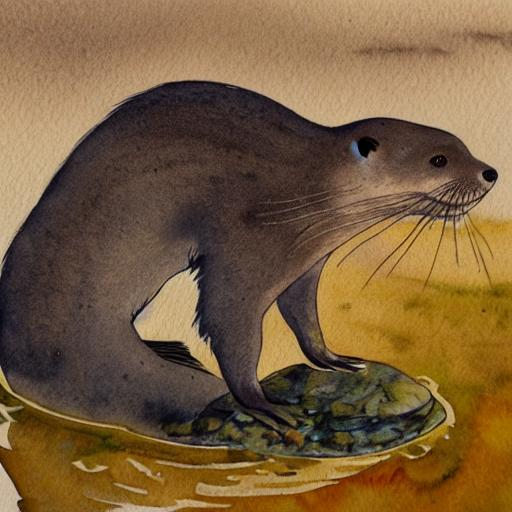

In [5]:
# Some settings
prompt = ["A watercolor painting of an otter"]
height = 512                        # default height of Stable Diffusion
width = 512                         # default width of Stable Diffusion
num_inference_steps = 30            # Number of denoising steps
guidance_scale = 7.5                # Scale for classifier-free guidance
generator = torch.manual_seed(32)   # Seed generator to create the inital latent noise
batch_size = 1

# Prep text
text_input = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
with torch.no_grad():
    text_embeddings = text_encoder(text_input.input_ids.to(torch_device))[0]
max_length = text_input.input_ids.shape[-1]
uncond_input = tokenizer(
    [""] * batch_size, padding="max_length", max_length=max_length, return_tensors="pt"
)
with torch.no_grad():
    uncond_embeddings = text_encoder(uncond_input.input_ids.to(torch_device))[0]
text_embeddings = torch.cat([uncond_embeddings, text_embeddings])

# Prep Scheduler
def set_timesteps(scheduler, num_inference_steps):
    scheduler.set_timesteps(num_inference_steps)
    scheduler.timesteps = scheduler.timesteps.to(torch.float32) # minor fix to ensure MPS compatibility, fixed in diffusers PR 3925

set_timesteps(scheduler,num_inference_steps)

# Prep latents
latents = torch.randn(
  (batch_size, unet.config.in_channels, height // 8, width // 8),
  generator=generator,
)
latents = latents.to(torch_device)
latents = latents * scheduler.init_noise_sigma # Scaling (previous versions did latents = latents * self.scheduler.sigmas[0]

# Loop
with autocast("cuda"):  # will fallback to CPU if no CUDA; no autocast for MPS
    for i, t in tqdm(enumerate(scheduler.timesteps), total=len(scheduler.timesteps)):
        # expand the latents if we are doing classifier-free guidance to avoid doing two forward passes.
        latent_model_input = torch.cat([latents] * 2)
        sigma = scheduler.sigmas[i]
        # Scale the latents (preconditioning):
        # latent_model_input = latent_model_input / ((sigma**2 + 1) ** 0.5) # Diffusers 0.3 and below
        latent_model_input = scheduler.scale_model_input(latent_model_input, t)

        # predict the noise residual
        with torch.no_grad():
            noise_pred = unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

        # perform guidance
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # compute the previous noisy sample x_t -> x_t-1
        # latents = scheduler.step(noise_pred, i, latents)["prev_sample"] # Diffusers 0.3 and below
        latents = scheduler.step(noise_pred, t, latents).prev_sample

# scale and decode the image latents with vae
latents = 1 / 0.18215 * latents
with torch.no_grad():
    image = vae.decode(latents).sample

# Display
image = (image / 2 + 0.5).clamp(0, 1)
image = image.detach().cpu().permute(0, 2, 3, 1).numpy()
images = (image * 255).round().astype("uint8")
pil_images = [Image.fromarray(image) for image in images]
pil_images[0]

It's working, but that's quite a bit of code! Let's look at the components one by one.

## The Autoencoder (AE)

The AE can 'encode' an image into some sort of latent representation, and decode this back into an image. I've wrapped the code for this into a couple of functions here so we can see what this looks like in action:

In [6]:
def pil_to_latent(input_im):
    # Single image -> single latent in a batch (so size 1, 4, 64, 64)
    with torch.no_grad():
        latent = vae.encode(tfms.ToTensor()(input_im).unsqueeze(0).to(torch_device)*2-1) # Note scaling
    return 0.18215 * latent.latent_dist.sample()

def latents_to_pil(latents):
    # bath of latents -> list of images
    latents = (1 / 0.18215) * latents
    with torch.no_grad():
        image = vae.decode(latents).sample
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.detach().cpu().permute(0, 2, 3, 1).numpy()
    images = (image * 255).round().astype("uint8")
    pil_images = [Image.fromarray(image) for image in images]
    return pil_images

We'll use a pic from the web here, but you can load your own instead by uploading it and editing the filename in the next cell.

In [7]:
# Download a demo Image
!curl --output macaw.jpg 'https://lafeber.com/pet-birds/wp-content/uploads/2018/06/Scarlet-Macaw-2.jpg'

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 62145  100 62145    0     0   372k      0 --:--:-- --:--:-- --:--:--  374k


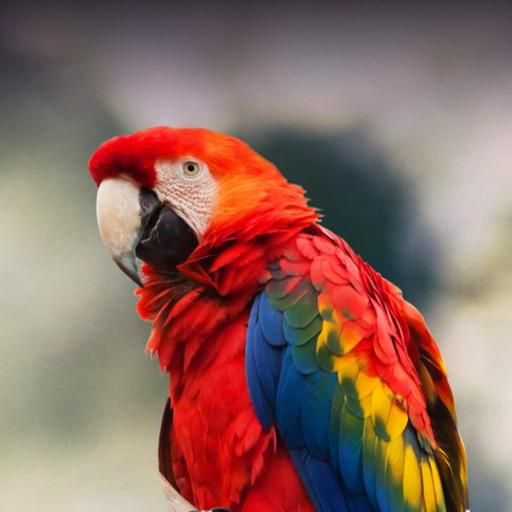

In [8]:
# Load the image with PIL
input_image = Image.open('macaw.jpg').resize((512, 512))
input_image

Encoding this into the latent space of the AE with the function defined above looks like this:

In [9]:
# Encode to the latent space
encoded = pil_to_latent(input_image)
encoded.shape

torch.Size([1, 4, 64, 64])

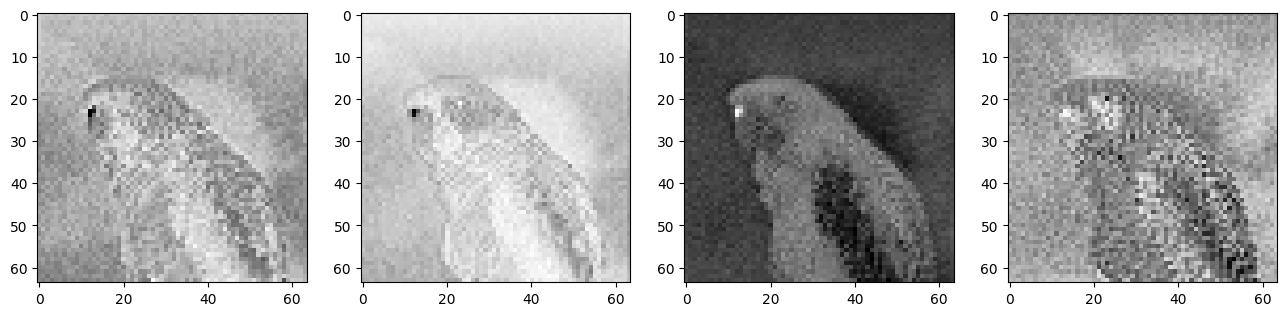

In [10]:
# Let's visualize the four channels of this latent representation:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for c in range(4):
    axs[c].imshow(encoded[0][c].cpu(), cmap='Greys')

This 4x64x64 tensor captures lots of information about the image, hopefully enough that when we feed it through the decoder we get back something very close to our input image:

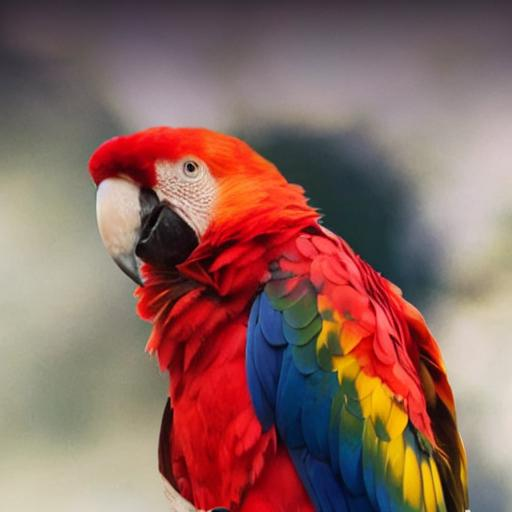

In [11]:
# Decode this latent representation back into an image
decoded = latents_to_pil(encoded)[0]
decoded

You'll see some small differences if you squint! Forcus on the eye if you can't see anything obvious. This is pretty impressive - that 4x64x64 latent seems to hold a lot more information that a 64px image...

This autoencoder has been trained to squish down an image to a smaller representation and then re-create the image back from this compressed version again.

In this particular case the compression factor is 48, we start with a 3x512x512(chxhtxwd) image and it get compressed to a latent vector 4x64x64. Each 3x8x8 pixel volume in the input image gets compressed down to just 4 numbers(4x1x1). You can find AEs with a higher compression ratio (eg f16 like some popular VQGAN models) but at some point they begin to introduce artifacts that we don't want.

Why do we even use an autoencoder? We can do diffusion in pixel space - where the model gets all the image data as inputs and produces an output prediction of the same shape. But this means processing a LOT of data, and make high-resolution generation very computationally expensive. Some solutions to this involve doing diffusion at low resolution (64px for eg) and then training a separate model to upscale repeatedly (as with D2/Imagen). But latent diffusion instead does the diffusion process in this 'latent space', using the compressed representations from our AE rather than raw images. These representations are information rich, and can be small enough to handle manageably on consumer hardware. Once we've generated a new 'image' as a latent representation, the autoencoder can take those final latent outputs and turn them into actual pixels.

# The Scheduler
Now we need to talk about adding noise...

During training, we add some noise to an image an then have the model try to predict the noise. If we always added a ton of noise, the model might not have much to work with. If we only add a tiny amount, the model won't be able to do much with the random starting points we use for sampling. So during training the amount is varied, according to some distribution.

During sampling, we want to 'denoise' over a number of steps. How many steps and how much noise we should aim for at each step are going to affect the final result.

The scheduler is in charge of handling all of these details. For example: `scheduler = LMSDiscreteScheduler(beta_start=0.00085, beta_end=0.012, beta_schedule="scaled_linear", num_train_timesteps=1000)` sets up a scheduler that matches the one used to train this model. When we want to sample over a smaller number of steps, we set this up with `scheduler.set_timesteps`:

In [12]:
# Setting the number of sampling steps:
set_timesteps(scheduler, 15)

You can see how our new set of steps corresponds to those used in training:

In [13]:
# See these in terms of the original 1000 steps used for training:
print(scheduler.timesteps)

tensor([999.0000, 927.6429, 856.2857, 784.9286, 713.5714, 642.2143, 570.8571,
        499.5000, 428.1429, 356.7857, 285.4286, 214.0714, 142.7143,  71.3571,
          0.0000])


And how much noise is present at each:

In [14]:
# Look at the equivalent noise levels:
print(scheduler.sigmas)

tensor([14.6146,  9.6826,  6.6780,  4.7746,  3.5221,  2.6666,  2.0606,  1.6156,
         1.2768,  1.0097,  0.7913,  0.6056,  0.4397,  0.2780,  0.0292,  0.0000])


During sampling, we'll start at a high noise level (in fact, our input will be pure noise) and gradually 'denoise' down to an image, according to this schedule.

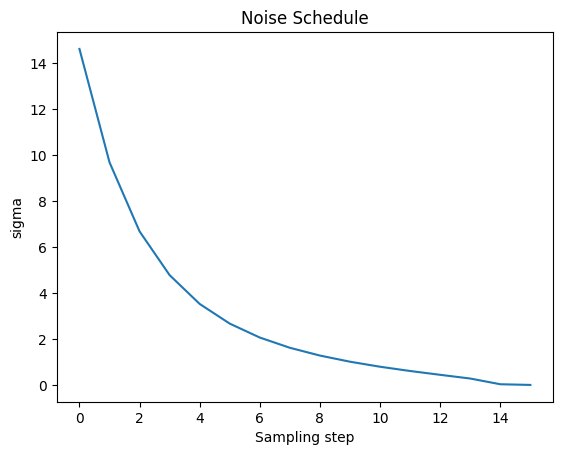

In [15]:
# Plotting this noise schedule:
plt.plot(scheduler.sigmas)
plt.title('Noise Schedule')
plt.xlabel('Sampling step')
plt.ylabel('sigma')
plt.show()

In [16]:
# TODO maybe show timestep as well

This 'sigma' is the amount of noise added to the latent representation. Let's visualize what this looks like by adding a bit of noise to our encoded image and then decoding this noised version:

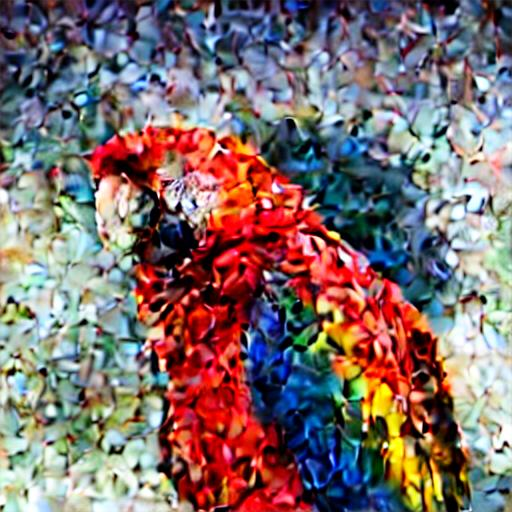

In [17]:
noise = torch.randn_like(encoded) # Random noise
sampling_step = 10 # Equivalent to step 10 out of 15 in the schedule above
# encoded_and_noised = scheduler.add_noise(encoded, noise, timestep) # Diffusers 0.3 and below
encoded_and_noised = scheduler.add_noise(encoded, noise, timesteps=torch.tensor([scheduler.timesteps[sampling_step]]))
latents_to_pil(encoded_and_noised.float())[0] # Display

What does this look like at different timesteps? Experiment and see for yourself!

If you uncomment the cell below you'll see that in this case the `scheduler.add_noise` function literally just adds noise scaled by sigma: `noisy_samples = original_samples + noise * sigmas`

In [18]:
# Additional experiments for the four original prompts; original examples are retained.
import csv, hashlib, json, time
import numpy as np
from datetime import datetime, timezone
from IPython.display import display

if QUICK_RUN or os.environ.get('COURSE_SMOKE') == '1':
    raise RuntimeError('The original parameter comparisons require full mode.')
if not torch.cuda.is_available():
    raise RuntimeError('Run these real-model comparisons in a hosted Colab GPU runtime.')
DD_SEED = 32
DD_ROOT = Path(COLAB_CONTEXT['folder']) / 'results' / '02_stable_diffusion_deep_dive_objective' / COLAB_CONTEXT['record'].stem
DD_ROOT.mkdir(parents=True, exist_ok=True)
DD_GROUPS = {}

def dd_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def dd_tensor_hash(tensor):
    return hashlib.sha256(tensor.detach().float().cpu().contiguous().numpy().tobytes()).hexdigest()

def dd_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + '.writing')
    temporary.write_text(json.dumps(value, indent=2, default=str) + '\n', encoding='utf-8')
    temporary.replace(path)

def dd_csv(path, rows):
    keys = list(dict.fromkeys(key for row in rows for key in row))
    with Path(path).open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=keys)
        writer.writeheader(); writer.writerows(rows)

def dd_scheduler(steps, start_step=None):
    # A NEW scheduler prevents a previous trial's LMS history/step_index leaking.
    fresh = LMSDiscreteScheduler.from_config(scheduler.config)
    set_timesteps(fresh, steps)
    if start_step is not None:
        fresh.set_begin_index(start_step)
    return fresh

def dd_noise(shape):
    # CPU generator gives identical initial noise for every setting, then transfers it.
    return torch.randn(shape, generator=torch.Generator(device='cpu').manual_seed(DD_SEED), dtype=torch.float32).to(torch_device)

def dd_embeddings(prompt_text):
    inputs = tokenizer(['', prompt_text], padding='max_length', max_length=tokenizer.model_max_length,
                       truncation=True, return_tensors='pt')
    with torch.no_grad():
        return text_encoder(inputs.input_ids.to(torch_device))[0]

def dd_generate(prompt_text, cfg=8.0, start_step=None, blue_scale=0.0, blue_every=5):
    # Every generation uses the original 512px model and 50-step LMS schedule.
    # UNet autocast limits GPU activation memory; all trials use the same policy.
    fresh = dd_scheduler(50, start_step)
    embeddings = dd_embeddings(prompt_text)
    initial_noise = dd_noise((1, unet.config.in_channels, 64, 64))
    initial_hash = dd_tensor_hash(initial_noise)
    first = 0 if start_step is None else int(start_step)
    if start_step is None:
        sample = initial_noise * fresh.init_noise_sigma
    else:
        sample = fresh.add_noise(encoded.detach().float(), initial_noise,
                                 fresh.timesteps[first:first+1].to(encoded.device))
    initial_latent_hash = dd_tensor_hash(sample)
    trace = []
    # Freeze only VAE parameters temporarily. Gradients still flow into the latents.
    original_flags = [parameter.requires_grad for parameter in vae.parameters()]
    if blue_scale:
        for parameter in vae.parameters(): parameter.requires_grad_(False)
    started = time.perf_counter()
    try:
        for offset, timestep in enumerate(fresh.timesteps[first:]):
            index = first + offset
            model_input = fresh.scale_model_input(torch.cat([sample] * 2), timestep)
            sigma = fresh.sigmas[fresh.step_index].to(sample.device)
            with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16):
                predicted = unet(model_input, timestep, encoder_hidden_states=embeddings).sample
            unconditional, conditional = predicted.chunk(2)
            predicted = unconditional + float(cfg) * (conditional - unconditional)
            raw_blue_loss = None; gradient_norm = None
            applied = bool(blue_scale and index % blue_every == 0)
            if applied:
                # Same low-memory approximate gradient as the original blue example:
                # UNet prediction is fixed; differentiate VAE output wrt noisy latents.
                sample = sample.detach().requires_grad_(True)
                predicted_clean = sample - sigma * predicted
                decoded_for_loss = vae.decode(predicted_clean / 0.18215).sample / 2 + 0.5
                raw_loss = blue_loss(decoded_for_loss)
                gradient = torch.autograd.grad(raw_loss * float(blue_scale), sample)[0]
                raw_blue_loss = float(raw_loss.detach())
                gradient_norm = float(gradient.detach().float().square().mean().sqrt())
                sample = sample.detach() - gradient * sigma.square()
                del decoded_for_loss, raw_loss, gradient, predicted_clean
            sample = fresh.step(predicted, timestep, sample).prev_sample.detach()
            if not torch.isfinite(sample).all():
                raise FloatingPointError(f'Nonfinite latent at step {index}; no successful result recorded.')
            trace.append({'sampling_step': index, 'training_timestep': float(timestep),
                          'sigma': float(sigma), 'blue_update_applied': applied,
                          'raw_blue_loss_before_update': raw_blue_loss, 'blue_gradient_rms': gradient_norm,
                          'latent_rms_after_update': float(sample.float().square().mean().sqrt())})
        with torch.no_grad():
            decoded = vae.decode(sample / 0.18215).sample / 2 + 0.5
        if not torch.isfinite(decoded).all(): raise FloatingPointError('Nonfinite decoded image.')
        final_raw_blue_error = float(torch.abs(decoded[:, 2] - 0.9).mean())
        pixels = (decoded.clamp(0, 1)[0].detach().cpu().permute(1, 2, 0).numpy() * 255).round().astype('uint8')
        image = Image.fromarray(pixels)
    finally:
        for parameter, flag in zip(vae.parameters(), original_flags): parameter.requires_grad_(flag)
    return image, trace, {'prompt': prompt_text, 'seed': DD_SEED, 'height': 512, 'width': 512,
                         'schedule_steps': 50, 'start_step': first, 'executed_denoising_steps': len(trace),
                         'guidance_scale': float(cfg), 'blue_loss_scale': float(blue_scale), 'blue_every': int(blue_every),
                         'blue_updates': sum(row['blue_update_applied'] for row in trace),
                         'noise_sha256': initial_hash, 'initial_latent_sha256': initial_latent_hash,
                         'encoded_input_sha256': dd_tensor_hash(encoded), 'seconds': time.perf_counter()-started,
                         'raw_final_blue_error_to_0_9': final_raw_blue_error,
                         'unet_compute_policy': 'CUDA float16 autocast; float32 latents and VAE guidance',
                         'guidance_gradient': 'original approximate gradient: fixed UNet prediction, differentiate VAE wrt latent'}

def dd_save(group, label, image, metrics, trace=None, reference=None):
    destination = DD_ROOT / group
    destination.mkdir(exist_ok=True)
    image_path = destination / (label + '.png')
    image.save(image_path)
    pixels = np.asarray(image).astype(np.float64) / 255.
    metrics = dict(metrics, label=label, image=image_path.relative_to(DD_ROOT).as_posix(), image_sha256=dd_hash(image_path),
                   mean_red=float(pixels[:, :, 0].mean()), mean_green=float(pixels[:, :, 1].mean()), mean_blue=float(pixels[:, :, 2].mean()),
                   pixel_std=float(pixels.std()), clipped_pixel_fraction=float(((pixels <= 0) | (pixels >= 1)).mean()),
                   displayed_blue_error_to_0_9=float(np.abs(pixels[:, :, 2]-0.9).mean()))
    if reference is not None:
        metrics['reference_pixel_mse'] = float(np.square(pixels - np.asarray(reference).astype(np.float64)/255.).mean())
    if trace is not None:
        trace_path = destination / (label + '_steps.csv'); dd_csv(trace_path, trace)
        metrics['trace'] = trace_path.relative_to(DD_ROOT).as_posix(); metrics['trace_sha256'] = dd_hash(trace_path)
    dd_json(destination / (label + '.json'), metrics)
    return metrics

def dd_group(group, rows, expected, prompt_index, complete=False):
    assert len(rows) <= expected
    if complete:
        assert len(rows) == expected and all((DD_ROOT / row['image']).is_file() and dd_hash(DD_ROOT / row['image']) == row['image_sha256'] for row in rows)
    DD_GROUPS[group] = {'source_prompt_zero_based_original': prompt_index, 'expected_trials': expected,
                        'saved_trials': len(rows), 'fully_executed': complete, 'trials': rows,
                        'quality_judgment': 'Inspect the genuine images; pixel measurements do not establish prompt quality or a subjective winner.'}
    dd_csv(DD_ROOT / group / 'comparison.csv', rows)
    dd_json(DD_ROOT / 'task_evidence.json', {'notebook': '02_stable_diffusion_deep_dive.ipynb',
            'recorded_utc': datetime.now(timezone.utc).isoformat(), 'synthetic': False,
            'model': 'CompVis/stable-diffusion-v1-4', 'model_commit': getattr(unet.config, '_commit_hash', None),
            'scheduler_class': type(scheduler).__name__, 'scheduler_config': dict(scheduler.config),
            'source_image_sha256': dd_hash(DD_ROOT / 'source_macaw.png'),
            'encoded_input_sha256': dd_tensor_hash(encoded), 'groups': DD_GROUPS,
            'all_four_experiments_executed': len(DD_GROUPS) == 4 and all(item['fully_executed'] for item in DD_GROUPS.values()),
            'learner_visual_interpretation_required': True, 'provider_completion_claimed': False})

def dd_display(group, images, labels):
    thumbnails = [image.resize((256, 256)) for image in images]
    grid = Image.new('RGB', (256 * len(images), 280), 'white')
    from PIL import ImageDraw
    drawing = ImageDraw.Draw(grid)
    for index, (image, label) in enumerate(zip(thumbnails, labels)):
        grid.paste(image, (index*256, 24)); drawing.text((index*256+4, 4), label, fill='black')
    grid.save(DD_ROOT / group / 'comparison_grid.png')
    display(grid)
    import pandas as pd
    display(pd.DataFrame(DD_GROUPS[group]['trials']))

input_image.convert('RGB').save(DD_ROOT / 'source_macaw.png')
print('Actual comparison images, step traces and task evidence will persist in:', DD_ROOT)


Actual comparison images, step traces and task evidence will persist in: /content/HaiLong_Colab_Exercises/04_fastai_part2/diffusion_intro/results/02_stable_diffusion_deep_dive_objective/02_stable_diffusion_deep_dive-20261019T043551-d89e5a


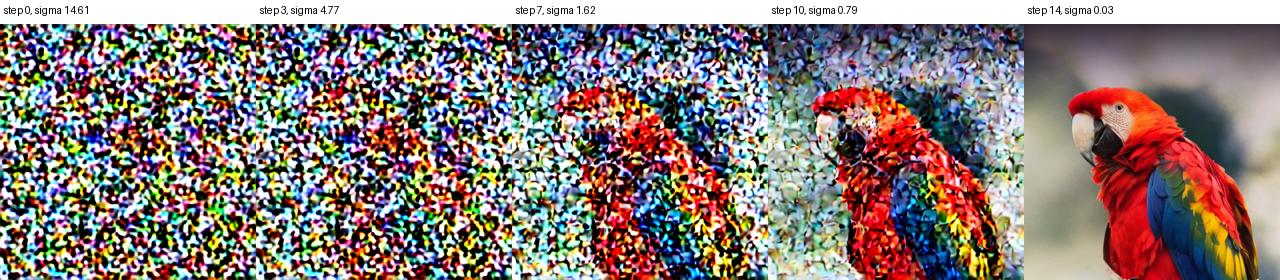

,seed,schedule_steps,sampling_step,training_timestep,sigma,latent_perturbation_rms,noise_sha256,encoded_input_sha256,label,image,image_sha256,mean_red,mean_green,mean_blue,pixel_std,clipped_pixel_fraction,displayed_blue_error_to_0_9,reference_pixel_mse
0,32,15,0,999.000000,14.614647,14.615140,ce13aebd4309fa1c181fdf355f00c88724b1c93bf0e779...,f4510ac1c45511484307bcf89f427f0430be17f0bc2103...,noise_step_00,noise_timesteps/noise_step_00.png,d4dd3fad79f77679b52223bb8479151a1463fd0074123a...,0.483767,0.472689,0.443925,0.389890,0.436598,0.497633,0.203934
1,32,15,3,784.928589,4.774591,4.774752,ce13aebd4309fa1c181fdf355f00c88724b1c93bf0e779...,f4510ac1c45511484307bcf89f427f0430be17f0bc2103...,noise_step_03,noise_timesteps/noise_step_03.png,7d837e3d6a1b4f86ece49e76cd88f614372c5884bdde7b...,0.488878,0.462774,0.449572,0.391610,0.436339,0.492963,0.180711
2,32,15,7,499.500000,1.615583,1.615638,ce13aebd4309fa1c181fdf355f00c88724b1c93bf0e779...,f4510ac1c45511484307bcf89f427f0430be17f0bc2103...,noise_step_07,noise_timesteps/noise_step_07.png,8e40df24a6faf3b734be12afdea76793ae6b3f7b341340...,0.480895,0.443902,0.448827,0.372618,0.346611,0.485205,0.114981
3,32,15,10,285.428558,0.791262,0.791288,ce13aebd4309fa1c181fdf355f00c88724b1c93bf0e779...,f4510ac1c45511484307bcf89f427f0430be17f0bc2103...,noise_step_10,noise_timesteps/noise_step_10.png,313bc32be0936f0758bd813d000150b0b9b5abe20309f1...,0.502761,0.420924,0.422428,0.310057,0.136954,0.485106,0.039076
4,32,15,14,0.000000,0.029168,0.029169,ce13aebd4309fa1c181fdf355f00c88724b1c93bf0e779...,f4510ac1c45511484307bcf89f427f0430be17f0bc2103...,noise_step_14,noise_timesteps/noise_step_14.png,a762ff85971046b6019a9d294c0367bdc807fb01000d81...,0.551291,0.405477,0.378345,0.252335,0.007816,0.521655,0.000678


In [19]:
# Original prompt 31: compare several noise timesteps with one fixed noise tensor.
noise_rows = []; noise_images = []; noise_labels = []
fixed_noise = dd_noise(encoded.shape)
for sampling_step in [0, 3, 7, 10, 14]:
    trial_scheduler = dd_scheduler(15)
    timestep = trial_scheduler.timesteps[sampling_step:sampling_step+1].to(encoded.device)
    noisy = trial_scheduler.add_noise(encoded.detach().float(), fixed_noise, timestep)
    sigma = trial_scheduler.sigmas[sampling_step].to(encoded.device)
    assert torch.allclose(noisy, encoded.detach().float() + fixed_noise*sigma, rtol=1e-5, atol=1e-5)
    image = latents_to_pil(noisy.float())[0]
    metrics = {'seed': DD_SEED, 'schedule_steps': 15, 'sampling_step': sampling_step,
               'training_timestep': float(timestep[0]), 'sigma': float(sigma),
               'latent_perturbation_rms': float((noisy-encoded).float().square().mean().sqrt()),
               'noise_sha256': dd_tensor_hash(fixed_noise), 'encoded_input_sha256': dd_tensor_hash(encoded)}
    label = f'noise_step_{sampling_step:02}'
    noise_rows.append(dd_save('noise_timesteps', label, image, metrics, reference=input_image))
    noise_images.append(image); noise_labels.append(f'step {sampling_step}, sigma {float(sigma):.2f}')
    dd_group('noise_timesteps', noise_rows, 5, 31)
assert len({row['noise_sha256'] for row in noise_rows}) == 1
dd_group('noise_timesteps', noise_rows, 5, 31, complete=True)
dd_display('noise_timesteps', noise_images, noise_labels)


In [20]:
# ??scheduler.add_noise

Other diffusion models may be trained with different noising and scheduling approaches, some of which keep the variance fairly constant across noise levels ('variance preserving') with different scaling and mixing tricks instead of having noisy latents with higher and higher variance as more noise is added ('variance exploding').

If we want to start from random noise instead of a noised image, we need to scale it by the largest sigma value used during training, ~14 in this case. And before these noisy latents are fed to the model they are scaled again in the so-called pre-conditioning step:
`latent_model_input = latent_model_input / ((sigma**2 + 1) ** 0.5)` (now handled by `latent_model_input = scheduler.scale_model_input(latent_model_input, t)`).

Again, this scaling/pre-conditioning differs between papers and implementations, so keep an eye out for this if you work with a different type of diffusion model.

## Loop starting from noised version of input (AKA image2image)

Let's see what happens when we use our image as a starting point, adding some noise and then doing the final few denoising steps in the loop with a new prompt.

We'll use a similar loop to the first demo, but we'll skip the first `start_step` steps.

To noise our image we'll use code like that shown above, using the scheduler to noise it to a level equivalent to step 10 (`start_step`).

  0%|          | 0/50 [00:00<?, ?it/s]

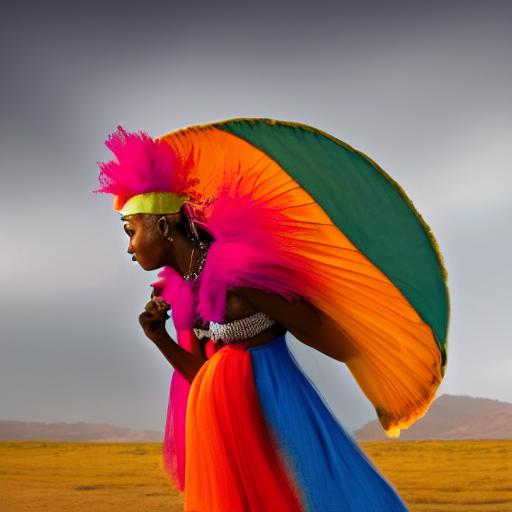

In [21]:
# Settings (same as before except for the new prompt)
prompt = ["A colorful dancer, nat geo photo"]
height = 512                        # default height of Stable Diffusion
width = 512                         # default width of Stable Diffusion
num_inference_steps = 50            # Number of denoising steps
guidance_scale = 8                  # Scale for classifier-free guidance
generator = torch.manual_seed(32)   # Seed generator to create the inital latent noise
batch_size = 1

# Prep text (same as before)
text_input = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
with torch.no_grad():
    text_embeddings = text_encoder(text_input.input_ids.to(torch_device))[0]
max_length = text_input.input_ids.shape[-1]
uncond_input = tokenizer(
    [""] * batch_size, padding="max_length", max_length=max_length, return_tensors="pt"
)
with torch.no_grad():
    uncond_embeddings = text_encoder(uncond_input.input_ids.to(torch_device))[0]
text_embeddings = torch.cat([uncond_embeddings, text_embeddings])

# Prep Scheduler (setting the number of inference steps)
set_timesteps(scheduler, num_inference_steps)

# Prep latents (noising appropriately for start_step)
start_step = 10
start_sigma = scheduler.sigmas[start_step]
noise = torch.randn_like(encoded)
latents = scheduler.add_noise(encoded, noise, timesteps=torch.tensor([scheduler.timesteps[start_step]]))
latents = latents.to(torch_device).float()

# Loop
for i, t in tqdm(enumerate(scheduler.timesteps), total=len(scheduler.timesteps)):
    if i >= start_step: # << This is the only modification to the loop we do

        # expand the latents if we are doing classifier-free guidance to avoid doing two forward passes.
        latent_model_input = torch.cat([latents] * 2)
        sigma = scheduler.sigmas[i]
        latent_model_input = scheduler.scale_model_input(latent_model_input, t)

        # predict the noise residual
        with torch.no_grad():
            noise_pred = unet(latent_model_input, t, encoder_hidden_states=text_embeddings)["sample"]

        # perform guidance
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # compute the previous noisy sample x_t -> x_t-1
        latents = scheduler.step(noise_pred, t, latents).prev_sample

latents_to_pil(latents)[0]

You can see that some colours and structure from the image are kept, but we now have a new picture! The more noise you add and the more steps you do, the further away it gets from the input image.

This is how the popular img2img pipeline works. Again, if this is your end goal there are tools to make this easy!

But you can see that under the hood this is the same as the generation loop just skipping the first few steps and starting from a noised image rather than pure noise.

Explore changing how many steps are skipped and see how this affects the amount the image changes from the input.

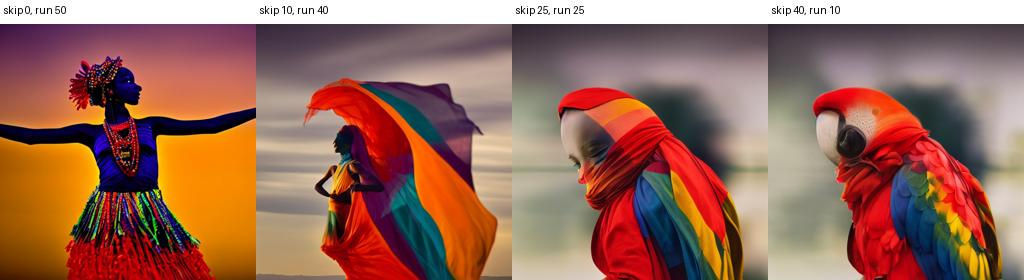

,prompt,seed,height,width,schedule_steps,start_step,executed_denoising_steps,guidance_scale,blue_loss_scale,blue_every,...,image_sha256,mean_red,mean_green,mean_blue,pixel_std,clipped_pixel_fraction,displayed_blue_error_to_0_9,reference_pixel_mse,trace,trace_sha256
0,"A colorful dancer, nat geo photo",32,512,512,50,0,50,8.0,0.0,5,...,64cd087147f006bc0e762e27e469fae45ecff8d0b953f8...,0.594642,0.303539,0.155065,0.304799,0.213023,0.745007,0.119417,img2img_skipped_steps/skip_00_steps.csv,c8234e35ef80ec5b16bc72a7ff51d0bc1433f9c34fcd0b...
1,"A colorful dancer, nat geo photo",32,512,512,50,10,40,8.0,0.0,5,...,0c4664037b0497aa71b20642fc472e55b06d7211148b80...,0.562363,0.367093,0.321966,0.254444,0.056623,0.578034,0.035644,img2img_skipped_steps/skip_10_steps.csv,94f41549eaab27bfcd7ddd034d450c1f907d1c18b8fd38...
2,"A colorful dancer, nat geo photo",32,512,512,50,25,25,8.0,0.0,5,...,d45b328cd2000e3f67aaeeb42563d3cc65341b2b234175...,0.557767,0.390817,0.355752,0.251479,0.008929,0.544248,0.010208,img2img_skipped_steps/skip_25_steps.csv,39427980ddca1deaa72292750d04df3418c88936b1fc9c...
3,"A colorful dancer, nat geo photo",32,512,512,50,40,10,8.0,0.0,5,...,4def249e984ab51e9977fcb89c744490cb62439b157246...,0.554123,0.400169,0.370463,0.252167,0.009602,0.529537,0.003090,img2img_skipped_steps/skip_40_steps.csv,5ba82171949c18a4d55fa2b1b3fb6b6acaa18731f572e5...


In [22]:
# Original prompt 36: vary only the skipped steps, retaining the 50-step schedule.
img2img_rows = []; img2img_images = []; img2img_labels = []
for skipped in [0, 10, 25, 40]:
    image, trace, metrics = dd_generate('A colorful dancer, nat geo photo', cfg=8, start_step=skipped)
    assert len(trace) == 50-skipped
    label = f'skip_{skipped:02}'
    img2img_rows.append(dd_save('img2img_skipped_steps', label, image, metrics, trace, input_image))
    img2img_images.append(image); img2img_labels.append(f'skip {skipped}, run {50-skipped}')
    dd_group('img2img_skipped_steps', img2img_rows, 4, 36)
assert len({row['noise_sha256'] for row in img2img_rows}) == 1
dd_group('img2img_skipped_steps', img2img_rows, 4, 36, complete=True)
dd_display('img2img_skipped_steps', img2img_images, img2img_labels)


## Exploring the text -> embedding pipeline

We use a text encoder model to turn our text into a set of 'embeddings' which are fed to the diffusion model as conditioning. Let's follow a piece of text through this process and see how it works.

In [23]:
# Our text prompt
prompt = 'A picture of a puppy'

We begin with tokenization:

In [24]:
# Turn the text into a sequnce of tokens:
text_input = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
text_input['input_ids'][0] # View the tokens

tensor([49406,   320,  1674,   539,   320,  6829, 49407, 49407, 49407, 49407,
        49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
        49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
        49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
        49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
        49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
        49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407, 49407,
        49407, 49407, 49407, 49407, 49407, 49407, 49407])

In [25]:
# See the individual tokens
for t in text_input['input_ids'][0][:8]: # We'll just look at the first 7 to save you from a wall of '<|endoftext|>'
    print(t, tokenizer.decoder.get(int(t)))

tensor(49406) <|startoftext|>
tensor(320) a</w>
tensor(1674) picture</w>
tensor(539) of</w>
tensor(320) a</w>
tensor(6829) puppy</w>
tensor(49407) <|endoftext|>
tensor(49407) <|endoftext|>


In [26]:
# TODO call out that 6829 is puppy

We can jump straight to the final (output) embeddings like so:

In [27]:
# Grab the output embeddings
output_embeddings = text_encoder(text_input.input_ids.to(torch_device))[0]
print('Shape:', output_embeddings.shape)
output_embeddings

Shape: torch.Size([1, 77, 768])


tensor([[[-0.3884,  0.0229, -0.0522,  ..., -0.4899, -0.3066,  0.0675],
         [ 0.0290, -1.3258,  0.3085,  ..., -0.5257,  0.9768,  0.6652],
         [ 0.6942,  0.3538,  1.0991,  ..., -1.5716, -1.2643, -0.0121],
         ...,
         [-0.0221, -0.0053, -0.0089,  ..., -0.7303, -1.3830, -0.3011],
         [-0.0062, -0.0246,  0.0065,  ..., -0.7326, -1.3745, -0.2953],
         [-0.0536,  0.0269,  0.0444,  ..., -0.7159, -1.3634, -0.3075]]],
       device='cuda:0', grad_fn=<NativeLayerNormBackward0>)

We pass our tokens through the text_encoder and we magically get some numbers we can feed to the model.

How are these generated? The tokens are transformed into a set of input embeddings, which are then fed through the transformer model to get the final output embeddings.

To get these input embeddings, there are actually two steps - as revealed by inspecting `text_encoder.text_model.embeddings`:

In [28]:
text_encoder.text_model.embeddings

CLIPTextEmbeddings(
  (token_embedding): Embedding(49408, 768)
  (position_embedding): Embedding(77, 768)
)

### Token embeddings

The token is fed to the `token_embedding` to transform it into a vector. The function name `get_input_embeddings` here is misleading since these token embeddings need to be combined with the position embeddings before they are actually used as inputs to the model! Anyway, let's look at just the token embedding part first

We can look at the embedding layer:

In [29]:
# Access the embedding layer
token_emb_layer = text_encoder.text_model.embeddings.token_embedding
token_emb_layer # Vocab size 49408, emb_dim 768

Embedding(49408, 768)

And embed a token like so:

In [30]:
# Embed a token - in this case the one for 'puppy'
embedding = token_emb_layer(torch.tensor(6829, device=torch_device))
embedding.shape # 768-dim representation

torch.Size([768])

This single token has been mapped to a 768-dimensional vector - the token embedding.

We can do the same with all of the tokens in the prompt to get all the token embeddings:

In [31]:
token_embeddings = token_emb_layer(text_input.input_ids.to(torch_device))
print(token_embeddings.shape) # batch size 1, 77 tokens, 768 values for each
token_embeddings

torch.Size([1, 77, 768])


tensor([[[ 0.0011,  0.0032,  0.0003,  ..., -0.0018,  0.0003,  0.0019],
         [ 0.0013, -0.0011, -0.0126,  ..., -0.0124,  0.0120,  0.0080],
         [ 0.0235, -0.0118,  0.0110,  ...,  0.0049,  0.0078,  0.0160],
         ...,
         [ 0.0012,  0.0077, -0.0011,  ..., -0.0015,  0.0009,  0.0052],
         [ 0.0012,  0.0077, -0.0011,  ..., -0.0015,  0.0009,  0.0052],
         [ 0.0012,  0.0077, -0.0011,  ..., -0.0015,  0.0009,  0.0052]]],
       device='cuda:0', grad_fn=<EmbeddingBackward0>)

### Positional Embeddings

Positional embeddings tell the model where in a sequence a token is. Much like the token embedding, this is a set of (optionally learnable) parameters. But now instead of dealing with ~50k tokens we just need one for each position (77 total):

In [32]:
pos_emb_layer = text_encoder.text_model.embeddings.position_embedding
pos_emb_layer

Embedding(77, 768)

We can get the positional embedding for each position:

In [33]:
position_ids = text_encoder.text_model.embeddings.position_ids[:, :77]
position_embeddings = pos_emb_layer(position_ids)
print(position_embeddings.shape)
position_embeddings

torch.Size([1, 77, 768])


tensor([[[ 0.0016,  0.0020,  0.0002,  ..., -0.0013,  0.0008,  0.0015],
         [ 0.0042,  0.0029,  0.0002,  ...,  0.0010,  0.0015, -0.0012],
         [ 0.0018,  0.0007, -0.0012,  ..., -0.0029, -0.0009,  0.0026],
         ...,
         [ 0.0216,  0.0055, -0.0101,  ..., -0.0065, -0.0029,  0.0037],
         [ 0.0188,  0.0073, -0.0077,  ..., -0.0025, -0.0009,  0.0057],
         [ 0.0330,  0.0281,  0.0289,  ...,  0.0160,  0.0102, -0.0310]]],
       device='cuda:0', grad_fn=<EmbeddingBackward0>)

### Combining token and position embeddings

Time to combine the two. How do we do this? Just add them! Other approaches are possible but for this model this is how it is done.

Combining them in this way gives us the final input embeddings ready to feed through the transformer model:

In [34]:
# And combining them we get the final input embeddings
input_embeddings = token_embeddings + position_embeddings
print(input_embeddings.shape)
input_embeddings

torch.Size([1, 77, 768])


tensor([[[ 2.6770e-03,  5.2133e-03,  4.9323e-04,  ..., -3.1321e-03,
           1.0659e-03,  3.4316e-03],
         [ 5.5371e-03,  1.7510e-03, -1.2381e-02,  ..., -1.1410e-02,
           1.3508e-02,  6.8378e-03],
         [ 2.5356e-02, -1.1019e-02,  9.7663e-03,  ...,  1.9460e-03,
           6.8375e-03,  1.8573e-02],
         ...,
         [ 2.2781e-02,  1.3262e-02, -1.1241e-02,  ..., -8.0054e-03,
          -2.0560e-03,  8.9366e-03],
         [ 2.0026e-02,  1.5015e-02, -8.7638e-03,  ..., -4.0313e-03,
           1.8487e-05,  1.0885e-02],
         [ 3.4206e-02,  3.5826e-02,  2.7768e-02,  ...,  1.4465e-02,
           1.1110e-02, -2.5745e-02]]], device='cuda:0', grad_fn=<AddBackward0>)

We can check that these are the same as the result we'd get from `text_encoder.text_model.embeddings`:

In [35]:
# The following combines all the above steps (but doesn't let us fiddle with them!)
text_encoder.text_model.embeddings(text_input.input_ids.to(torch_device))

tensor([[[ 2.6770e-03,  5.2133e-03,  4.9323e-04,  ..., -3.1321e-03,
           1.0659e-03,  3.4316e-03],
         [ 5.5371e-03,  1.7510e-03, -1.2381e-02,  ..., -1.1410e-02,
           1.3508e-02,  6.8378e-03],
         [ 2.5356e-02, -1.1019e-02,  9.7663e-03,  ...,  1.9460e-03,
           6.8375e-03,  1.8573e-02],
         ...,
         [ 2.2781e-02,  1.3262e-02, -1.1241e-02,  ..., -8.0054e-03,
          -2.0560e-03,  8.9366e-03],
         [ 2.0026e-02,  1.5015e-02, -8.7638e-03,  ..., -4.0313e-03,
           1.8487e-05,  1.0885e-02],
         [ 3.4206e-02,  3.5826e-02,  2.7768e-02,  ...,  1.4465e-02,
           1.1110e-02, -2.5745e-02]]], device='cuda:0', grad_fn=<AddBackward0>)

### Feeding these through the transformer model

![transformer diagram](https://github.com/johnowhitaker/tglcourse/raw/main/images/text_encoder_noborder.png)

We want to mess with these input embeddings (specifically the token embeddings) before we send them through the rest of the model, but first we should check that we know how to do that. I read the code of the text_encoders `forward` method, and based on that the code for the `forward` method of the text_model that the text_encoder wraps. To inspect it yourself, type `??text_encoder.text_model.forward` and you'll get the function info and source code - a useful debugging trick!

Anyway, based on that we can copy in the bits we need to get the so-called 'last hidden state' and thus generate our final embeddings:

In [36]:
def get_output_embeds(input_embeddings):
    # CLIP's text model uses causal mask, so we prepare it here:
    bsz, seq_len = input_embeddings.shape[:2]
    # Explicit additive causal mask avoids a removed private Transformers method.
    causal_attention_mask = torch.full((bsz,1,seq_len,seq_len),
        torch.finfo(input_embeddings.dtype).min, dtype=input_embeddings.dtype,
        device=input_embeddings.device).triu(diagonal=1)

    # Getting the output embeddings involves calling the model with passing output_hidden_states=True
    # so that it doesn't just return the pooled final predictions:
    encoder_outputs = text_encoder.text_model.encoder(
        inputs_embeds=input_embeddings,
        attention_mask=None, # We aren't using an attention mask so that can be None
        causal_attention_mask=causal_attention_mask.to(torch_device),
        output_attentions=None,
        output_hidden_states=True, # We want the output embs not the final output
    )

    # We're interested in the output hidden state only
    output = encoder_outputs[0]

    # There is a final layer norm we need to pass these through
    output = text_encoder.text_model.final_layer_norm(output)

    # And now they're ready!
    return output

out_embs_test = get_output_embeds(input_embeddings) # Feed through the model with our new function
print(out_embs_test.shape) # Check the output shape
out_embs_test # Inspect the output

torch.Size([1, 77, 768])


tensor([[[-0.3884,  0.0229, -0.0522,  ..., -0.4899, -0.3066,  0.0675],
         [ 0.0290, -1.3258,  0.3085,  ..., -0.5257,  0.9768,  0.6652],
         [ 0.6942,  0.3538,  1.0991,  ..., -1.5716, -1.2643, -0.0121],
         ...,
         [-0.0221, -0.0053, -0.0089,  ..., -0.7303, -1.3830, -0.3011],
         [-0.0062, -0.0246,  0.0065,  ..., -0.7326, -1.3745, -0.2953],
         [-0.0536,  0.0269,  0.0444,  ..., -0.7159, -1.3634, -0.3075]]],
       device='cuda:0', grad_fn=<NativeLayerNormBackward0>)

Note that these match the `output_embeddings` we saw near the start - we've figured out how to split up that one step ("get the text embeddings") into multiple sub-steps ready for us to modify.

Now that we have this process in place, we can replace the input embedding of a token with a new one of our choice - which in our final use-case will be something we learn. To demonstrate the concept though, let's replace the input embedding for 'puppy' in the prompt we've been playing with with the embedding for token 2368, get a new set of output embeddings based on this, and use these to generate an image to see what we get:

In [37]:
prompt = 'A picture of a puppy'

# Tokenize
text_input = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
input_ids = text_input.input_ids.to(torch_device)

# Get token embeddings
token_embeddings = token_emb_layer(input_ids)

# The new embedding. In this case just the input embedding of token 2368...
replacement_token_embedding = text_encoder.get_input_embeddings()(torch.tensor(2368, device=torch_device))

# Insert this into the token embeddings (
token_embeddings[0, torch.where(input_ids[0]==6829)] = replacement_token_embedding.to(torch_device)

# Combine with pos embs
input_embeddings = token_embeddings + position_embeddings

#  Feed through to get final output embs
modified_output_embeddings = get_output_embeds(input_embeddings)

print(modified_output_embeddings.shape)
modified_output_embeddings

torch.Size([1, 77, 768])


tensor([[[-0.3884,  0.0229, -0.0522,  ..., -0.4899, -0.3066,  0.0675],
         [ 0.0290, -1.3258,  0.3085,  ..., -0.5257,  0.9768,  0.6652],
         [ 0.6942,  0.3538,  1.0991,  ..., -1.5716, -1.2643, -0.0121],
         ...,
         [-0.6034, -0.5322,  0.0629,  ..., -0.3964,  0.0877, -0.9558],
         [-0.5936, -0.5407,  0.0731,  ..., -0.3876,  0.0906, -0.9436],
         [-0.6393, -0.4703,  0.1103,  ..., -0.3904,  0.1351, -0.9726]]],
       device='cuda:0', grad_fn=<NativeLayerNormBackward0>)

The first few are the same, the last aren't. Everything at and after the position of the token we're replacing will be affected.

If all went well, we should see something other than a puppy when we use these to generate an image. And sure enough, we do!

In [38]:
#Generating an image with these modified embeddings

def generate_with_embs(text_embeddings):
    height = 512                        # default height of Stable Diffusion
    width = 512                         # default width of Stable Diffusion
    num_inference_steps = 30            # Number of denoising steps
    guidance_scale = 7.5                # Scale for classifier-free guidance
    generator = torch.manual_seed(32)   # Seed generator to create the inital latent noise
    batch_size = 1

    max_length = text_input.input_ids.shape[-1]
    uncond_input = tokenizer(
      [""] * batch_size, padding="max_length", max_length=max_length, return_tensors="pt"
    )
    with torch.no_grad():
        uncond_embeddings = text_encoder(uncond_input.input_ids.to(torch_device))[0]
    text_embeddings = torch.cat([uncond_embeddings, text_embeddings])

    # Prep Scheduler
    set_timesteps(scheduler, num_inference_steps)

    # Prep latents
    latents = torch.randn(
    (batch_size, unet.config.in_channels, height // 8, width // 8),
    generator=generator,
    )
    latents = latents.to(torch_device)
    latents = latents * scheduler.init_noise_sigma

    # Loop
    for i, t in tqdm(enumerate(scheduler.timesteps), total=len(scheduler.timesteps)):
        # expand the latents if we are doing classifier-free guidance to avoid doing two forward passes.
        latent_model_input = torch.cat([latents] * 2)
        sigma = scheduler.sigmas[i]
        latent_model_input = scheduler.scale_model_input(latent_model_input, t)

        # predict the noise residual
        with torch.no_grad():
            noise_pred = unet(latent_model_input, t, encoder_hidden_states=text_embeddings)["sample"]

        # perform guidance
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # compute the previous noisy sample x_t -> x_t-1
        latents = scheduler.step(noise_pred, t, latents).prev_sample

    return latents_to_pil(latents)[0]

  0%|          | 0/30 [00:00<?, ?it/s]

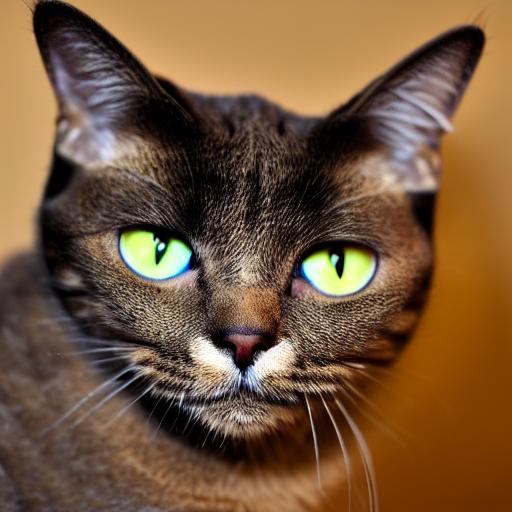

In [39]:
generate_with_embs(modified_output_embeddings)

Suprise! Now you know what token 2368 means ;)

**What can we do with this?** Why did we go to all of this trouble? Well, we'll see a more compelling use-case shortly but the tl;dr is that once we can access and modify the token embeddings we can do tricks like replacing them with something else. In the example we just did, that was just another token embedding from the model's vocabulary, equivalent to just editing the prompt. But we can also mix tokens - for example, here's a half-puppy-half-skunk:

In [40]:
# In case you're wondering how to get the token for a word, or the embedding for a token:
prompt = 'skunk'
print('tokenizer(prompt):', tokenizer(prompt))
print('token_emb_layer([token_id]) shape:', token_emb_layer(torch.tensor([8797], device=torch_device)).shape)

tokenizer(prompt): {'input_ids': [49406, 42194, 49407], 'attention_mask': [1, 1, 1]}
token_emb_layer([token_id]) shape: torch.Size([1, 768])


  0%|          | 0/30 [00:00<?, ?it/s]

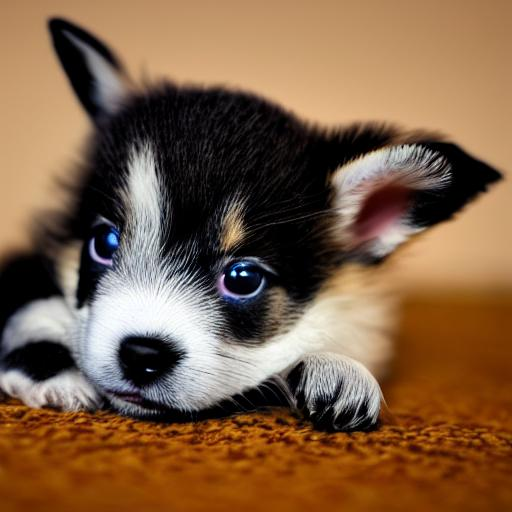

In [41]:
prompt = 'A picture of a puppy'

# Tokenize
text_input = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
input_ids = text_input.input_ids.to(torch_device)

# Get token embeddings
token_embeddings = token_emb_layer(input_ids)

# The new embedding. Which is now a mixture of the token embeddings for 'puppy' and 'skunk'
puppy_token_embedding = token_emb_layer(torch.tensor(6829, device=torch_device))
skunk_token_embedding = token_emb_layer(torch.tensor(42194, device=torch_device))
replacement_token_embedding = 0.5*puppy_token_embedding + 0.5*skunk_token_embedding

# Insert this into the token embeddings (
token_embeddings[0, torch.where(input_ids[0]==6829)] = replacement_token_embedding.to(torch_device)

# Combine with pos embs
input_embeddings = token_embeddings + position_embeddings

#  Feed through to get final output embs
modified_output_embeddings = get_output_embeds(input_embeddings)

# Generate an image with these
generate_with_embs(modified_output_embeddings)

### Textual Inversion

OK, so we can slip in a modified token embedding, and use this to generate an image. We used the token embedding for 'cat' in the above example, but what if instead could 'learn' a new token embedding for a specific concept? This is the idea behind 'Textual Inversion', in which a few example images are used to create a new token embedding:

![Overview image from the blog post](https://textual-inversion.github.io/static/images/training/training.JPG)
_Diagram from the [textual inversion blog post](https://textual-inversion.github.io/static/images/training/training.JPG) - note it doesn't show the positional embeddings step for simplicity_

We won't cover how this training works, but we can try loading one of these new 'concepts' from the [community-created SD concepts library](https://huggingface.co/sd-concepts-library) and see how it fits in with our example above. I'll use https://huggingface.co/sd-concepts-library/birb-style since it was the first one I made :) Download the learned_embeds.bin file from there and upload the file to wherever this notebook is before running this next cell:

In [42]:
birb_embed = torch.load('learned_embeds.bin', map_location='cpu', weights_only=True)
birb_embed.keys(), birb_embed['<birb-style>'].shape

(dict_keys(['<birb-style>']), torch.Size([768]))

We get a dictionary with a key (the special placeholder I used, <birb-style>) and the corresponding token embedding. As in the previous example, let's replace the 'puppy' token embedding with this and see what happens:

  0%|          | 0/30 [00:00<?, ?it/s]

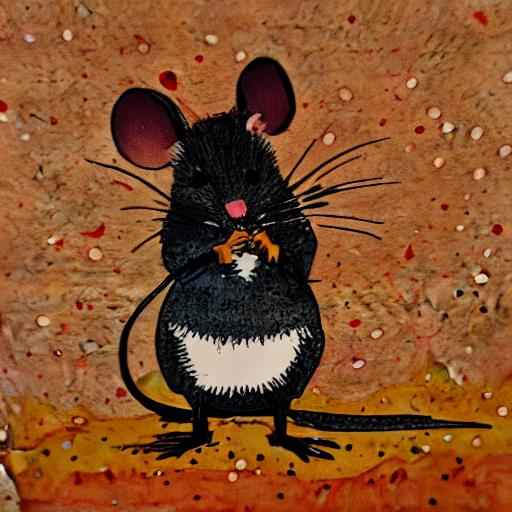

In [43]:
prompt = 'A mouse in the style of puppy'

# Tokenize
text_input = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
input_ids = text_input.input_ids.to(torch_device)

# Get token embeddings
token_embeddings = token_emb_layer(input_ids)

# The new embedding - our special birb word
replacement_token_embedding = birb_embed['<birb-style>'].to(torch_device)

# Insert this into the token embeddings
token_embeddings[0, torch.where(input_ids[0]==6829)] = replacement_token_embedding.to(torch_device)

# Combine with pos embs
input_embeddings = token_embeddings + position_embeddings

#  Feed through to get final output embs
modified_output_embeddings = get_output_embeds(input_embeddings)

# And generate an image with this:
generate_with_embs(modified_output_embeddings)

The token for 'puppy' was replaced with one that captures a particular style of painting, but it could just as easily represent a specific object or class of objects.

Again, there is [a nice inference notebook ](https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/stable_conceptualizer_inference.ipynb) from hf to make it easy to use the different concepts, that properly handles using the names in prompts ("A \<cat-toy> in the style of \<birb-style>") without worrying about all this manual stuff. The goal of this notebook is to pull back the curtain a bit so you know what is going on behind the scenes :)

## Messing with Embeddings

Besides just replacing the token embedding of a single word, there are various other tricks we can try. For example, what if we create a 'chimera' by averaging the embeddings of two different prompts?

  0%|          | 0/30 [00:00<?, ?it/s]

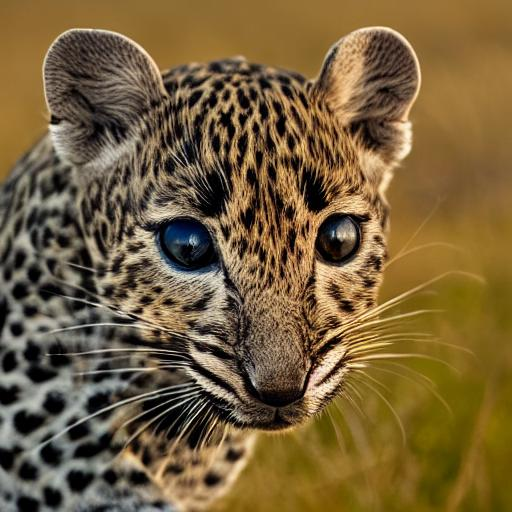

In [44]:
# Embed two prompts
text_input1 = tokenizer(["A mouse"], padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
text_input2 = tokenizer(["A leopard"], padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
with torch.no_grad():
    text_embeddings1 = text_encoder(text_input1.input_ids.to(torch_device))[0]
    text_embeddings2 = text_encoder(text_input2.input_ids.to(torch_device))[0]

# Mix them together
mix_factor = 0.35
mixed_embeddings = (text_embeddings1*mix_factor + \
                   text_embeddings2*(1-mix_factor))

# Generate!
generate_with_embs(mixed_embeddings)

## The UNET and CFG

Now it's time we looked at the actual diffusion model. This is typically a Unet that takes in the noisy latents (x) and predicts the noise. We use a conditional model that also takes in the timestep (t) and our text embedding (aka encoder_hidden_states) as conditioning. Feeding all of these into the model looks like this:
`noise_pred = unet(latents, t, encoder_hidden_states=text_embeddings)["sample"]`

We can try it out and see what the output looks like:

In [45]:
# Prep Scheduler
set_timesteps(scheduler, num_inference_steps)

# What is our timestep
t = scheduler.timesteps[0]
sigma = scheduler.sigmas[0]

# A noisy latent
latents = torch.randn(
  (batch_size, unet.config.in_channels, height // 8, width // 8),
  generator=generator,
)
latents = latents.to(torch_device)
latents = latents * scheduler.init_noise_sigma

# Text embedding
text_input = tokenizer(['A macaw'], padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
with torch.no_grad():
    text_embeddings = text_encoder(text_input.input_ids.to(torch_device))[0]

# Run this through the unet to predict the noise residual
with torch.no_grad():
    noise_pred = unet(latents, t, encoder_hidden_states=text_embeddings)["sample"]

latents.shape, noise_pred.shape # We get preds in the same shape as the input

(torch.Size([1, 4, 64, 64]), torch.Size([1, 4, 64, 64]))

Given a set of noisy latents, the model predicts the noise component. We can remove this noise from the noisy latents to see what the output image looks like (`latents_x0 = latents - sigma * noise_pred`). And we can add most of the noise back to this predicted output to get the (slightly less noisy hopefully) input for the next diffusion step. To visualize this let's generate another image, saving both the predicted output (x0) and the next step (xt-1) after every step:

In [46]:
prompt = 'Oil painting of an otter in a top hat'
height = 512
width = 512
num_inference_steps = 50
guidance_scale = 8
generator = torch.manual_seed(32)
batch_size = 1

# Make a folder to store results
Path('steps').mkdir(exist_ok=True)

# Prep text
text_input = tokenizer([prompt], padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
with torch.no_grad():
    text_embeddings = text_encoder(text_input.input_ids.to(torch_device))[0]
max_length = text_input.input_ids.shape[-1]
uncond_input = tokenizer(
    [""] * batch_size, padding="max_length", max_length=max_length, return_tensors="pt"
)
with torch.no_grad():
    uncond_embeddings = text_encoder(uncond_input.input_ids.to(torch_device))[0]
text_embeddings = torch.cat([uncond_embeddings, text_embeddings])

# Prep Scheduler
set_timesteps(scheduler, num_inference_steps)

# Prep latents
latents = torch.randn(
  (batch_size, unet.config.in_channels, height // 8, width // 8),
  generator=generator,
)
latents = latents.to(torch_device)
latents = latents * scheduler.init_noise_sigma

# Loop
for i, t in tqdm(enumerate(scheduler.timesteps), total=len(scheduler.timesteps)):
    # expand the latents if we are doing classifier-free guidance to avoid doing two forward passes.
    latent_model_input = torch.cat([latents] * 2)
    sigma = scheduler.sigmas[i]
    latent_model_input = scheduler.scale_model_input(latent_model_input, t)

    # predict the noise residual
    with torch.no_grad():
        noise_pred = unet(latent_model_input, t, encoder_hidden_states=text_embeddings)["sample"]

    # perform guidance
    noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
    noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

    # Get the predicted x0:
    # latents_x0 = latents - sigma * noise_pred # Calculating ourselves
    scheduler_step = scheduler.step(noise_pred, t, latents)
    latents_x0 = scheduler_step.pred_original_sample # Using the scheduler (Diffusers 0.4 and above)

    # compute the previous noisy sample x_t -> x_t-1
    latents = scheduler_step.prev_sample

    # To PIL Images
    im_t0 = latents_to_pil(latents_x0)[0]
    im_next = latents_to_pil(latents)[0]

    # Combine the two images and save for later viewing
    im = Image.new('RGB', (1024, 512))
    im.paste(im_next, (0, 0))
    im.paste(im_t0, (512, 0))
    im.save(f'steps/{i:04}.jpeg')

  0%|          | 0/50 [00:00<?, ?it/s]

In [47]:
# Make and show the progress video (change width to 1024 for full res)
!ffmpeg -v 1 -y -f image2 -framerate 12 -i steps/%04d.jpeg -c:v libx264 -preset slow -qp 18 -pix_fmt yuv420p out.mp4
mp4 = open('out.mp4','rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML("""
<video width=600 controls>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)

<IPython.core.display.HTML object>

The version on the right shows the predicted 'final output' (x0) at each step, and this is what is usually used for progress videos etc. The version on the left is the 'next step'. I found it interesteing to compare the two - watching the progress videos only you'd think drastic changes are happening expecially at early stages, but since the changes made per-step are relatively small the actual process is much more gradual.



### Classifier Free Guidance

By default, the model doesn't often do what we ask. If we want it to follow the prompt better, we use a hack called CFG. There's a good explanation in this video (AI coffee break GLIDE).

In the code, this comes down to us doing:

`noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)`

This works suprisingly well :) Explore changing the guidance_scale in the code above and see how this affects the results. How high can you push it before the results get worse?

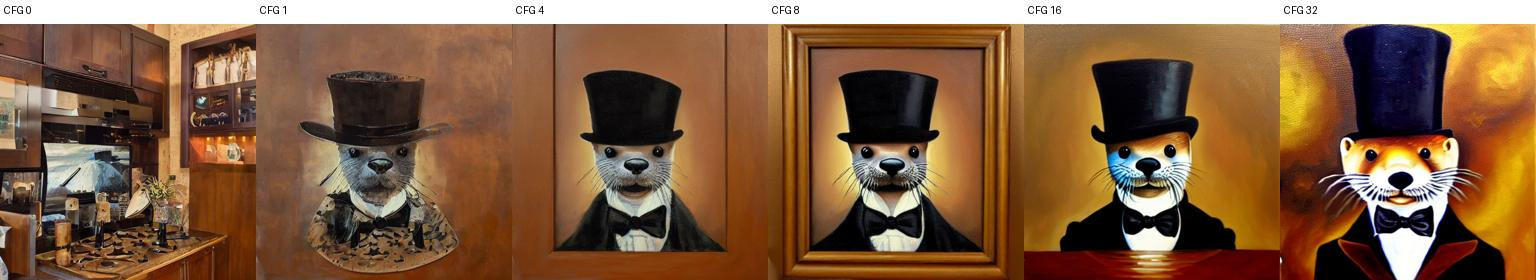

,prompt,seed,height,width,schedule_steps,start_step,executed_denoising_steps,guidance_scale,blue_loss_scale,blue_every,...,image,image_sha256,mean_red,mean_green,mean_blue,pixel_std,clipped_pixel_fraction,displayed_blue_error_to_0_9,trace,trace_sha256
0,Oil painting of an otter in a top hat,32,512,512,50,0,50,0.0,0.0,5,...,classifier_free_guidance/cfg_00.png,53fe318c15dc890da8381c89d63c4cc89ca32cd87256e8...,0.450917,0.321005,0.232141,0.230124,0.002726,0.667866,classifier_free_guidance/cfg_00_steps.csv,03c6180b62cbd7ff6b65bbd8e16d96b288148d3ff0f674...
1,Oil painting of an otter in a top hat,32,512,512,50,0,50,1.0,0.0,5,...,classifier_free_guidance/cfg_01.png,00607b309b30bd1a8189158df08504fb027c86b37b291d...,0.457830,0.323632,0.233698,0.171784,0.000551,0.666302,classifier_free_guidance/cfg_01_steps.csv,cea557b209573ecbab65facd7cee49237a23c626f569b8...
2,Oil painting of an otter in a top hat,32,512,512,50,0,50,4.0,0.0,5,...,classifier_free_guidance/cfg_04.png,a9b88a95dab60c30ebcdeb663fce51691b9e11f5bcd311...,0.473435,0.312764,0.195950,0.206936,0.001695,0.704051,classifier_free_guidance/cfg_04_steps.csv,c77fd03d471ad1d1f6f271b06fa68c5af913ce34ba0fcd...
3,Oil painting of an otter in a top hat,32,512,512,50,0,50,8.0,0.0,5,...,classifier_free_guidance/cfg_08.png,7de2dafbdb58e1125d1c0e183fbb62ca845bea5b6e4073...,0.466936,0.311136,0.162431,0.248942,0.051876,0.737595,classifier_free_guidance/cfg_08_steps.csv,909ef0e108cf2bb4bfcfae39309d6d4591d9543890e221...
4,Oil painting of an otter in a top hat,32,512,512,50,0,50,16.0,0.0,5,...,classifier_free_guidance/cfg_16.png,898f91fde3e1df6790df991d663ea4a6213cf5bf3642b1...,0.483895,0.328435,0.164649,0.270756,0.128375,0.738493,classifier_free_guidance/cfg_16_steps.csv,e3c153ec3e2e77006221e051567352761d748e268a78ea...
5,Oil painting of an otter in a top hat,32,512,512,50,0,50,32.0,0.0,5,...,classifier_free_guidance/cfg_32.png,da81ae15f3142b15f8a21ee612ddf283839a75f18b8d8e...,0.510175,0.340542,0.197769,0.334024,0.184614,0.713371,classifier_free_guidance/cfg_32_steps.csv,498fb82510e782ccda0e9fff611e825e32a2aff25f1b91...


Compare prompt adherence and artifacts in the grid. Clipping and pixel spread are diagnostics, not automatic quality scores.


In [48]:
# Original prompt 87: include unconditioned, weak, original and excessive CFG values.
cfg_rows = []; cfg_images = []; cfg_labels = []
for cfg_scale in [0, 1, 4, 8, 16, 32]:
    image, trace, metrics = dd_generate('Oil painting of an otter in a top hat', cfg=cfg_scale)
    assert len(trace) == 50
    label = f'cfg_{cfg_scale:02}'
    cfg_rows.append(dd_save('classifier_free_guidance', label, image, metrics, trace))
    cfg_images.append(image); cfg_labels.append(f'CFG {cfg_scale}')
    dd_group('classifier_free_guidance', cfg_rows, 6, 87)
assert len({row['initial_latent_sha256'] for row in cfg_rows}) == 1
dd_group('classifier_free_guidance', cfg_rows, 6, 87, complete=True)
dd_display('classifier_free_guidance', cfg_images, cfg_labels)
print('Compare prompt adherence and artifacts in the grid. Clipping and pixel spread are diagnostics, not automatic quality scores.')


## Sampling

There is still some complexity hidden from us inside `latents = scheduler.step(noise_pred, i, latents)["prev_sample"]`. How exactly does the sampler go from the current noisy latents to a slightly less noisy version? Why don't we just use the model in a single step? Are there other ways to view this?

The model tries to predict the noise in an image. For low noise values, we assume it does a pretty good job. For higher noise levels, it has a hard task! So instead of producing a perfect image, the results tend to look like a blurry mess - see the start of the video above for a visual! So, samplers use the model predictions to move a small amount towards the model prediction (removing some of the noise) and then get another prediction based on this marginally-less-rubbish input, and hope that this iteratively improves the result.

Different samplers do this in different ways. You can try to inspect the code for the default LMS sampler with:

In [49]:
# ??scheduler.step

**Time to draw some diagrams!** (Whiteboard/paper interlude)

### Authored digital diagram for the original drawing interlude

This is a digital Colab adaptation of the source paper/whiteboard activity,
explaining the following classifier-free/custom blue-guidance code. It is authored
instructional material; physical drawing or independent learner participation is
not claimed. The gradient branch treats the UNet predictions as frozen, as the
original `torch.no_grad()` code does, and updates the latent before the normal LMS
scheduler step. The original code's sigma scaling and VAE factor are shown.


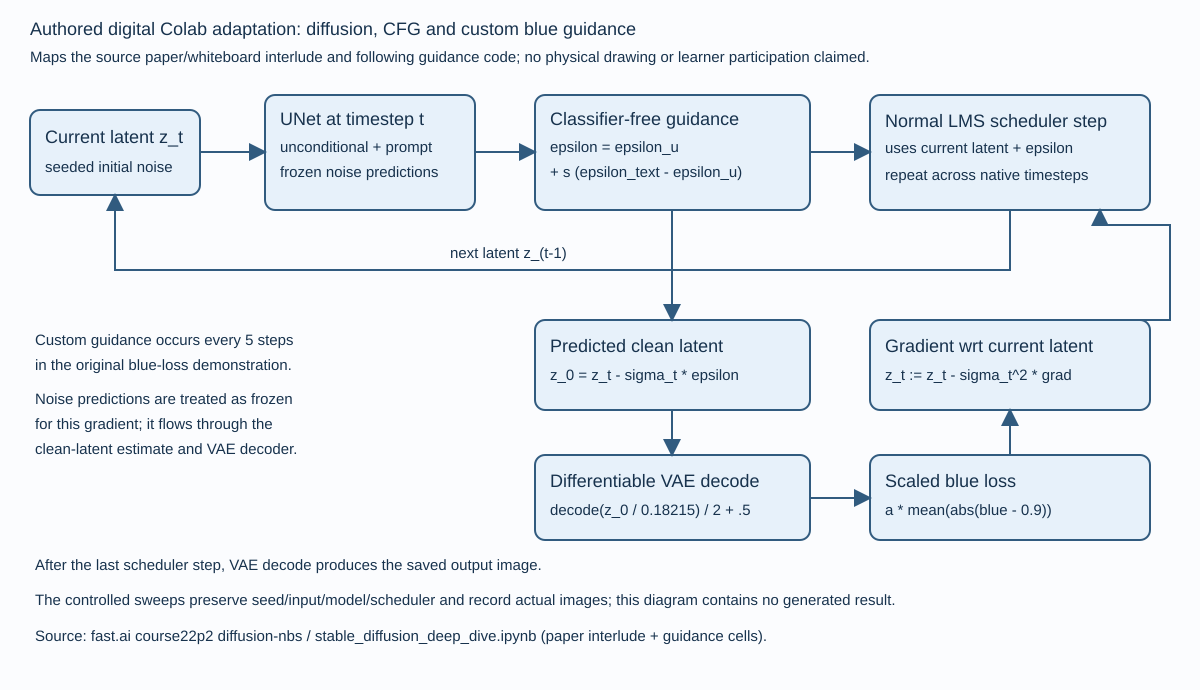

In [50]:
# Authored digital diagram; no inference or learner manual practice is claimed.
from IPython.display import SVG, display
diagram_source = COURSE_ROOT / '03_fastai/resources/diffusion_cfg_custom_guidance.svg'
diagram_svg = diagram_source.read_text(encoding='utf-8')
diagram_path = Path('results') / 'authored_diffusion_cfg_custom_guidance.svg'
diagram_path.parent.mkdir(parents=True, exist_ok=True)
diagram_path.write_text(diagram_svg, encoding='utf-8')
display(SVG(diagram_svg))


# Guidance


OK, final trick! How can we add some extra control to this generation process?

At each step, we're going to use our model as before to predict the noise component of x. Then we'll use this to produce a predicted output image, and apply some loss function to this image.

This function can be anything, but let's demo with a super simple example. If we want images that have a lot of blue, we can craft a loss function that gives a high loss if pixels have a low blue component:

In [51]:
def blue_loss(images):
    # How far are the blue channel values to 0.9:
    error = torch.abs(images[:,2] - 0.9).mean() # [:,2] -> all images in batch, only the blue channel
    return error

During each update step, we find the gradient of the loss with respect to the current noisy latents, and tweak them in the direction that reduces this loss as well as performing the normal update step:

  0%|          | 0/50 [00:00<?, ?it/s]

0 loss: 181.97967529296875


10 loss: 43.132957458496094


20 loss: 15.511751174926758


30 loss: 9.964906692504883


40 loss: 8.906630516052246


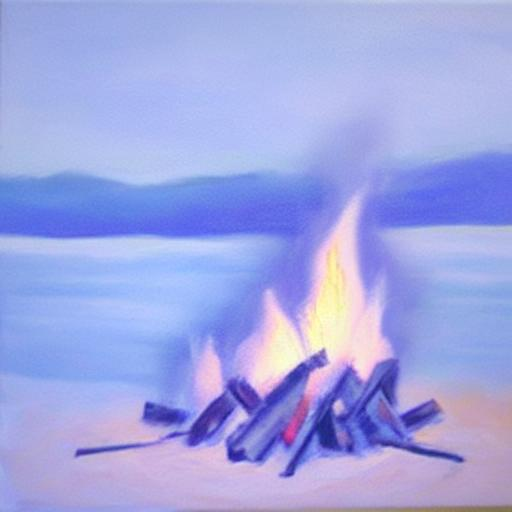

In [52]:
prompt = 'A campfire (oil on canvas)' #@param
height = 512                        # default height of Stable Diffusion
width = 512                         # default width of Stable Diffusion
num_inference_steps = 50  #@param           # Number of denoising steps
guidance_scale = 8 #@param               # Scale for classifier-free guidance
generator = torch.manual_seed(32)   # Seed generator to create the inital latent noise
batch_size = 1
blue_loss_scale = 200 #@param

# Prep text
text_input = tokenizer([prompt], padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")
with torch.no_grad():
    text_embeddings = text_encoder(text_input.input_ids.to(torch_device))[0]

# And the uncond. input as before:
max_length = text_input.input_ids.shape[-1]
uncond_input = tokenizer(
    [""] * batch_size, padding="max_length", max_length=max_length, return_tensors="pt"
)
with torch.no_grad():
    uncond_embeddings = text_encoder(uncond_input.input_ids.to(torch_device))[0]
text_embeddings = torch.cat([uncond_embeddings, text_embeddings])

# Prep Scheduler
set_timesteps(scheduler, num_inference_steps)

# Prep latents
latents = torch.randn(
  (batch_size, unet.config.in_channels, height // 8, width // 8),
  generator=generator,
)
latents = latents.to(torch_device)
latents = latents * scheduler.init_noise_sigma

# Loop
for i, t in tqdm(enumerate(scheduler.timesteps), total=len(scheduler.timesteps)):
    # expand the latents if we are doing classifier-free guidance to avoid doing two forward passes.
    latent_model_input = torch.cat([latents] * 2)
    sigma = scheduler.sigmas[i]
    latent_model_input = scheduler.scale_model_input(latent_model_input, t)

    # predict the noise residual
    with torch.no_grad():
        noise_pred = unet(latent_model_input, t, encoder_hidden_states=text_embeddings)["sample"]

    # perform CFG
    noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
    noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

    #### ADDITIONAL GUIDANCE ###
    if i%5 == 0:
        # Requires grad on the latents
        latents = latents.detach().requires_grad_()

        # Get the predicted x0:
        latents_x0 = latents - sigma * noise_pred
        # latents_x0 = scheduler.step(noise_pred, t, latents).pred_original_sample

        # Decode to image space
        denoised_images = vae.decode((1 / 0.18215) * latents_x0).sample / 2 + 0.5 # range (0, 1)

        # Calculate loss
        loss = blue_loss(denoised_images) * blue_loss_scale

        # Occasionally print it out
        if i%10==0:
            print(i, 'loss:', loss.item())

        # Get gradient
        cond_grad = torch.autograd.grad(loss, latents)[0]

        # Modify the latents based on this gradient
        latents = latents.detach() - cond_grad * sigma**2

    # Now step with scheduler
    latents = scheduler.step(noise_pred, t, latents).prev_sample


latents_to_pil(latents)[0]

Tweak the scale (`blue_loss_scale`) - at low values, the image is mostly red and orange thanks to the prompt. At higher values, it is mostly bluish! Too high and we get a plain blue image.

Since this is slow, you'll notice that I only apply this loss once every 5 iterations - this was a suggestion from Jeremy and we left it in because for this demo it saves time and still works. For your own tests you may want to explore using a lower scale for the loss and applying it every iteration instead :)

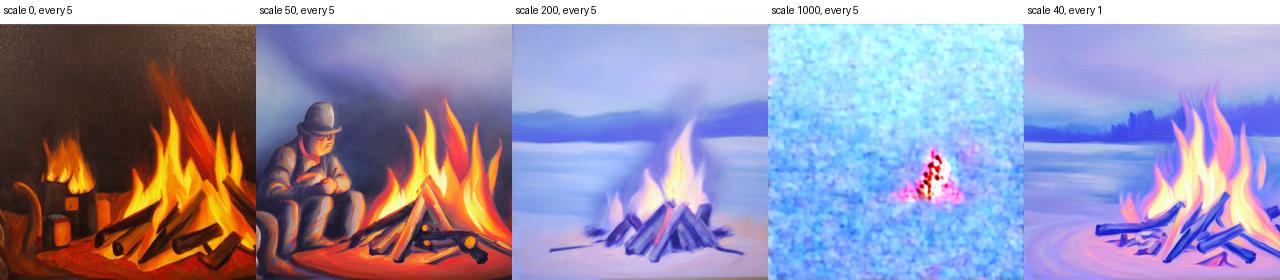

,prompt,seed,height,width,schedule_steps,start_step,executed_denoising_steps,guidance_scale,blue_loss_scale,blue_every,...,image,image_sha256,mean_red,mean_green,mean_blue,pixel_std,clipped_pixel_fraction,displayed_blue_error_to_0_9,trace,trace_sha256
0,A campfire (oil on canvas),32,512,512,50,0,50,8.0,0.0,5,...,blue_guidance/blue_0000_every_5.png,884458e37bc95c5116f962b96aaa62df77e4a13ff621a0...,0.427625,0.219499,0.095549,0.226370,0.014235,0.804451,blue_guidance/blue_0000_every_5_steps.csv,47ad250837d01b39a90a0ccdb0e5267fc99f0945d58c26...
1,A campfire (oil on canvas),32,512,512,50,0,50,8.0,50.0,5,...,blue_guidance/blue_0050_every_5.png,68873f3621e0e3715b25c65f911923d443c874a958fd10...,0.547918,0.414160,0.458905,0.235081,0.005141,0.441095,blue_guidance/blue_0050_every_5_steps.csv,a2bb6cd372e7226e717943d76e6cfb1bd753d1edf4d331...
2,A campfire (oil on canvas),32,512,512,50,0,50,8.0,200.0,5,...,blue_guidance/blue_0200_every_5.png,45daea4e3b183d256d9e79c8e3bd177e04261be9a5ec78...,0.626093,0.651738,0.889856,0.166541,0.000740,0.044797,blue_guidance/blue_0200_every_5_steps.csv,592e14ffd593d39466d32e0a6a2dfcdc2d4329642f016d...
3,A campfire (oil on canvas),32,512,512,50,0,50,8.0,1000.0,5,...,blue_guidance/blue_1000_every_5.png,13a39414226ccf83477703be5954381d042aa0074072fb...,0.577639,0.785881,0.992542,0.204577,0.338791,0.102513,blue_guidance/blue_1000_every_5_steps.csv,c186b47ad1a80216058d7b93b0d2c7ac0ab88c10f8e331...
4,A campfire (oil on canvas),32,512,512,50,0,50,8.0,40.0,1,...,blue_guidance/blue_0040_every_1.png,a0e8952fad91bcb27a1ebdc2f852793b0fa5e469c8da0c...,0.643855,0.613418,0.885741,0.194232,0.010202,0.040910,blue_guidance/blue_0040_every_1_steps.csv,6f6fec15968c741fc41069eb01007979fc6db865ae6973...


Compare the measured blue error, channel means and image variation alongside the generated images.
Four objective comparisons saved: /content/HaiLong_Colab_Exercises/04_fastai_part2/diffusion_intro/results/02_stable_diffusion_deep_dive_objective/02_stable_diffusion_deep_dive-20261019T043551-d89e5a/task_evidence.json


In [53]:
# Original prompt 95: strength sweep plus the suggested lower-scale/every-step experiment.
blue_rows = []; blue_images = []; blue_labels = []
for loss_scale, every in [(0, 5), (50, 5), (200, 5), (1000, 5), (40, 1)]:
    image, trace, metrics = dd_generate('A campfire (oil on canvas)', cfg=8, blue_scale=loss_scale, blue_every=every)
    assert len(trace) == 50
    assert metrics['blue_updates'] == (0 if loss_scale == 0 else len(range(0, 50, every)))
    label = f'blue_{loss_scale:04}_every_{every}'
    blue_rows.append(dd_save('blue_guidance', label, image, metrics, trace))
    blue_images.append(image); blue_labels.append(f'scale {loss_scale}, every {every}')
    dd_group('blue_guidance', blue_rows, 5, 95)
assert len({row['initial_latent_sha256'] for row in blue_rows}) == 1
dd_group('blue_guidance', blue_rows, 5, 95, complete=True)
dd_display('blue_guidance', blue_images, blue_labels)
print('Compare the measured blue error, channel means and image variation alongside the generated images.')
print('Four objective comparisons saved:', DD_ROOT / 'task_evidence.json')


NB: We should set latents requires_grad=True **before** we do the forward pass of the unet (removing `with torch.no_grad()`) if we want mode accurate gradients. BUT this requires a lot of extra memory. You'll see both approaches used depending on whose implementation you're looking at.

Guiding with classifier models can give you images of a specific class. Guiding with a model like CLIP can help better match a text prompt. Guiding with a style loss can help add a particular style. Guiding with some sort of perceptual loss can force it towards the overall look af a target image. And so on.

# Conclusions

Hopefully now you have a slightly better idea of what is happening when you make an image with one of these models, and how you can modify the process in creative ways. I hope you're inspired to make something fun :)

This notebook was written by Jonathan Whitaker, adapted from ['Grokking Stable Diffusion']([PRIVATE_CLOUD_LINK_OMITTED]) which was my early attempts to understand these components for myself. If you spot bugs or have questions, feel free to reach out to me @johnowhitaker :) Enjoy!

Save your outputs

Run the following cell after finishing. Choose **File > Save** in Colab to preserve your code and displayed results. Files in `results/` and `models/` persist in Drive when enabled.

In [54]:
finish_run(COLAB_CONTEXT)

Saved run settings. Save the notebook in Colab to keep its cell outputs.


In [55]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
    'base_model_commit': getattr(getattr(globals().get('model'), 'config', None), '_commit_hash', None),
}
_hailong_context = globals().get('COLAB_CONTEXT')
if _hailong_context and _hailong_context['folder'].relative_to(_hailong_context['root']).as_posix().startswith(('03_fastai', '04_fastai_part2')):
    from course_persistence import collect_reuse_evidence as _hailong_collect
    _hailong_evidence['fastai_reuse_evidence'] = _hailong_context['run'].get('reuse_evidence') or _hailong_collect(_hailong_context)
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": null, "legacy_keras": null, "base_model_commit": null, "fastai_reuse_evidence": {"contract_version": 1, "notebook": "04_fastai_part2/diffusion_intro/02_stable_diffusion_deep_dive.ipynb", "source_sha256": "ca43be24ca0fe8d2cb2a2e9e6095e31876429ea030404680c92a0558e2fb1f25", "helper_sha256": {"03_fastai/convolution_workbook_exercise.py": "ecacb93aef6846c82d6a9eebc4809e1a6766410f04783ac132f247935af3a8fc", "03_fastai/fastai_utils.py": "a03e913e1c07f55aedd56ee6128096f3f952f4f8be22f83c4a22002589c4bd18", "03_fastai/wearable_objective_extension.py": "f9b0a8bf81a5bab8c10aee5e8795e9cef3df58e40925f7705e58301b18b3fbe9", "03_fastai/wearable_utils.py": "6de4ee45118d96e024bd4e0f3fd3552905b38a1ff01c0a5146578bb0d8263db9", "04_fastai_part2/miniai/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855", "04_fastai_part2/miniai/_modidx.py": "21ec4929aaeca2cde3710b3f069ff8032fc